# The Calculus 1 Extra - 04. Calculus 1 Extra Practice with Integrals - Vol 2


<img src="./pics/cover.png" width=300> 

In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
!python --version

Python 3.13.13


In [3]:
pwd

'c:\\Users\\crodr\\Tutoriales\\Math\\Math_Tutor_DVD_Review\\Calculus_1_Extra_Practice\\04. Calculus 1 Extra Practice with Integrals - Vol 2'

In [4]:
C, n = sp.symbols("C, n", positive=True)
V, A, r, t, x, y, z, theta = sp.symbols("V, A, r, t, x, y, z, theta", real=True)
f, g, h = sp.symbols("f, g, h", cls=sp.Function)

In [5]:
# Add root folder to sys.path
sys.path.append(str(Path("../..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, setup_math_axes


## Video 01. Area Between Two Curves, Part 1


<img src="./pics/Fig01_01.png" width=600> 


$$A = \int_a^b [f(x) - g(x)] \, dx$$

### Exercise 1
Area between:

$$f(x) = x^2 \quad ; \quad g(x) = x^3 \quad \quad [-2,1]$$

In [11]:
f = x**2
g = x**3
A = sp.Integral(f - g, (x, -2, 1))
answer = A.doit()
display(Math(rf"{sp.latex(A)} = {sp.latex(answer)}"))

<IPython.core.display.Math object>

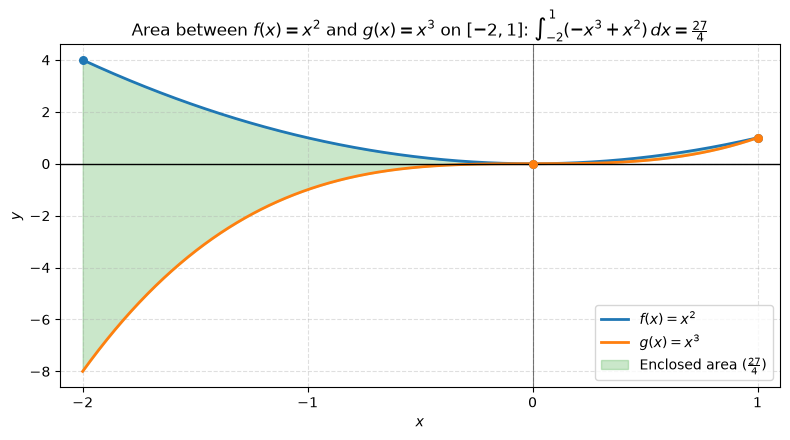

In [13]:
f_sym = x**2
g_sym = x**3

f_num = sp.lambdify(x, f_sym, "numpy")
g_num = sp.lambdify(x, g_sym, "numpy")

# Sample x values across [-2, 1] (plus a small margin to see intersection at x = 1 clearly)
x_vals = np.linspace(-2.0, 1.0, 1000)
y_f = f_num(x_vals)
y_g = g_num(x_vals)

fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot both curves
ax.plot(x_vals, y_f, color="tab:blue", linewidth=2, label=r"$f(x) = x^2$")
ax.plot(x_vals, y_g, color="tab:orange", linewidth=2, label=r"$g(x) = x^3$")

# Shade the area between f(x) and g(x) on [-2, 1]
ax.fill_between(
    x_vals,
    y_f,
    y_g,
    color="tab:green",
    alpha=0.25,
    interpolate=True,
    label=r"Enclosed area ($\frac{27}{4}$)",
)

# Mark key points: endpoints and intersection at (0, 0) and (1, 1)
key_x = [-2, 0, 1]
ax.scatter(key_x, f_num(np.array(key_x)), color="tab:blue", zorder=5, s=30)
ax.scatter([0, 1], g_num(np.array([0, 1])), color="tab:orange", zorder=5, s=30)

# Axes and styling
ax.axhline(0, color="black", linewidth=1)
ax.axvline(0, color="black", linewidth=0.8, alpha=0.5)
ax.set_xlim(-2.1, 1.1)
ax.set_xticks([-2, -1, 0, 1])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_title(
    r"Area between $f(x) = x^2$ and $g(x) = x^3$ on $[-2, 1]$: $\int_{-2}^{1}(-x^3 + x^2)\,dx = \frac{27}{4}$"
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()